# Reducción de dimensionalidad mediante PCA
## Breast Cancer Wisconsin
**Objetivo:** reducir las 30 variables predictoras a una representación de menor dimensión y evaluar la varianza conservada. Las etiquetas de diagnóstico no se utilizan para ajustar PCA; se reservan para colorear la visualización posterior.

## 1. Importación de librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Carga y descripción del dataset

In [3]:
datos = load_breast_cancer(as_frame=True)
X = datos.data.copy()
y = datos.target.copy()
print("Dimensiones:", X.shape)
print("Clases originales:", datos.target_names)
display(X.head())
display(X.describe().T)

Dimensiones: (569, 30)
Clases originales: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


El conjunto contiene 569 observaciones y 30 variables numéricas calculadas a partir de imágenes digitalizadas de aspirados de masa mamaria. La etiqueta de diagnóstico se mantiene separada del procedimiento PCA.

## 3. Exploración inicial

In [4]:
print("Tipos de datos:")
display(X.dtypes.value_counts())
print("Faltantes por variable:")
display(X.isna().sum().sort_values(ascending=False).head())
print("Faltantes totales:", X.isna().sum().sum())
print("Registros duplicados:", X.duplicated().sum())
print("Valores únicos por variable:")
display(X.nunique().sort_values().head())

Tipos de datos:


float64    30
Name: count, dtype: int64

Faltantes por variable:


mean radius        0
mean texture       0
mean perimeter     0
mean area          0
mean smoothness    0
dtype: int64

Faltantes totales: 0
Registros duplicados: 0
Valores únicos por variable:


worst smoothness    411
mean symmetry       432
mean radius         456
worst radius        457
mean smoothness     474
dtype: int64

## 4. Limpieza y validación de datos
Se revisan faltantes, duplicados, tipos de datos, variables constantes y posibles valores atípicos. Un valor extremo no se elimina automáticamente: primero debe determinarse si es un error o una observación válida.

In [5]:
faltantes = int(X.isna().sum().sum())
duplicados = int(X.duplicated().sum())
no_numericas = X.select_dtypes(exclude=np.number).columns.tolist()
constantes = X.columns[X.nunique() <= 1].tolist()
print(f"Faltantes: {faltantes}")
print(f"Duplicados: {duplicados}")
print(f"Columnas no numéricas: {no_numericas}")
print(f"Variables constantes: {constantes}")

Faltantes: 0
Duplicados: 0
Columnas no numéricas: []
Variables constantes: []


In [6]:
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
atipicos = ((X < q1 - 1.5*iqr) | (X > q3 + 1.5*iqr)).sum()
resumen_atipicos = pd.DataFrame({"cantidad_IQR": atipicos, "porcentaje": (atipicos/len(X)*100).round(2)}).sort_values("cantidad_IQR", ascending=False)
display(resumen_atipicos.head(15))

,cantidad_IQR,porcentaje
area error,65,11.42
radius error,38,6.68
perimeter error,38,6.68
worst area,35,6.15
smoothness error,30,5.27
fractal dimension error,28,4.92
compactness error,28,4.92
symmetry error,27,4.75
mean area,25,4.39
worst fractal dimension,24,4.22


**Decisión de limpieza:** no se imputan ni eliminan observaciones automáticamente. Si las verificaciones confirman ausencia de faltantes, duplicados y variables constantes, se conserva el conjunto completo. Los valores señalados por IQR son candidatos a revisión, no errores demostrados.

## 5. Preparación y estandarización

In [7]:
# El diagnóstico y se reserva para colorear la gráfica, no entra a PCA.
escalador = StandardScaler()
X_std = escalador.fit_transform(X)
print("Dimensiones estandarizadas:", X_std.shape)
print("Media primera variable:", X_std[:, 0].mean())
print("Desviación estándar primera variable:", X_std[:, 0].std())

Dimensiones estandarizadas: (569, 30)
Media primera variable: -1.3736327053358703e-16
Desviación estándar primera variable: 1.0


La estandarización evita que las variables con magnitudes numéricas mayores dominen la construcción de los componentes.

## 6. Aplicación de PCA y selección de componentes

In [8]:
pca = PCA()
X_pca = pca.fit_transform(X_std)
var_ind = pca.explained_variance_ratio_
var_acum = np.cumsum(var_ind)
tabla = pd.DataFrame({"componente": np.arange(1, len(var_ind)+1), "varianza_explicada": var_ind, "varianza_acumulada": var_acum})
display(tabla.round(4))

,componente,varianza_explicada,varianza_acumulada
0,1,0.4427,0.4427
1,2,0.1897,0.6324
2,3,0.0939,0.7264
3,4,0.0660,0.7924
4,5,0.0550,0.8473
5,6,0.0402,0.8876
6,7,0.0225,0.9101
7,8,0.0159,0.9260
8,9,0.0139,0.9399
9,10,0.0117,0.9516


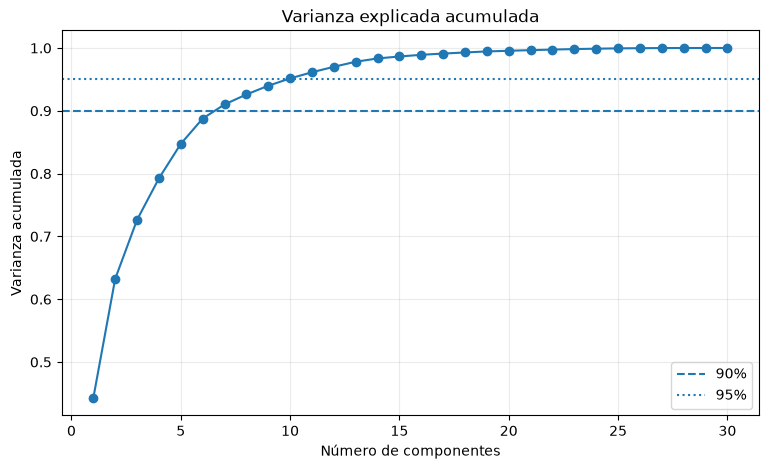

Componentes para 90%: 7
Componentes para 95%: 10


In [9]:
plt.figure(figsize=(9,5))
plt.plot(range(1, len(var_acum)+1), var_acum, marker="o")
plt.axhline(.90, ls="--", label="90%")
plt.axhline(.95, ls=":", label="95%")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada")
plt.grid(alpha=.25); plt.legend(); plt.show()
n90 = np.argmax(var_acum >= .90)+1
n95 = np.argmax(var_acum >= .95)+1
print("Componentes para 90%:", n90)
print("Componentes para 95%:", n95)

Se toma el 95 % como referencia de conservación de variabilidad, no como regla universal. La elección final depende del equilibrio entre compresión e información conservada.

## 7. Visualización en dos dimensiones

Varianza PC1 + PC2: 63.24 %


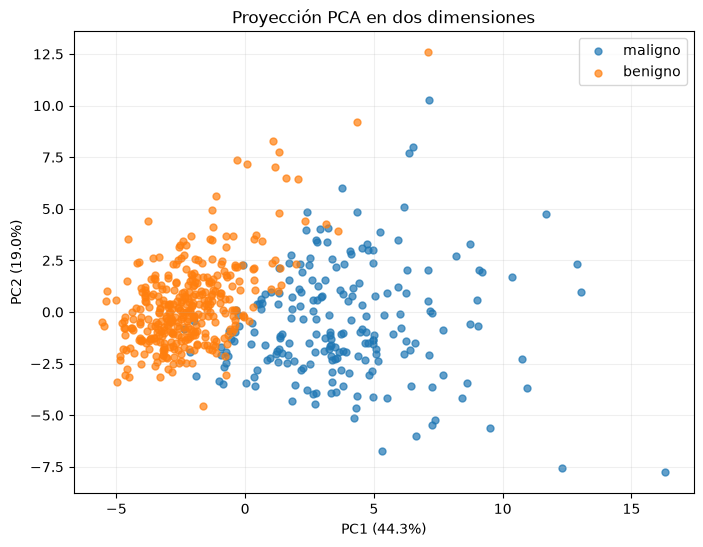

In [10]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_std)
print("Varianza PC1 + PC2:", round(pca2.explained_variance_ratio_.sum()*100, 2), "%")
nombres = {0: "maligno", 1: "benigno"}
plt.figure(figsize=(8,6))
for clase in np.unique(y):
    m = y.to_numpy() == clase
    plt.scatter(X_2d[m,0], X_2d[m,1], s=25, alpha=.7, label=nombres[clase])
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Proyección PCA en dos dimensiones")
plt.legend(); plt.grid(alpha=.2); plt.show()

## 8. Comparación del espacio original y reducido

In [11]:
comparacion = pd.DataFrame({
 "representacion": ["Original", "PCA - 2 componentes", f"PCA - {n95} componentes"],
 "numero_variables": [X.shape[1], 2, n95],
 "varianza_conservada_pct": [100, pca2.explained_variance_ratio_.sum()*100, var_acum[n95-1]*100]
})
display(comparacion.round(2))

,representacion,numero_variables,varianza_conservada_pct
0,Original,30,100.00
1,PCA - 2 componentes,2,63.24
2,PCA - 10 componentes,10,95.16


La proyección en dos componentes facilita la visualización, pero conserva menos variabilidad que una representación con más componentes. La comparación evidencia el compromiso entre compresión y conservación de información.

## 9. Interpretación y limitaciones
- PCA es no supervisado y lineal: maximiza la varianza de combinaciones de variables.
- La varianza explicada no equivale necesariamente a conservar toda la información útil para una tarea predictiva.
- Los componentes son combinaciones de variables originales y pueden ser menos interpretables.
- Una proyección 2D puede ocultar estructuras presentes en dimensiones superiores.
- Las etiquetas solo se usan para colorear la gráfica, nunca para ajustar PCA.

## 10. Conclusiones
PCA permite representar el conjunto con menos dimensiones. El número de componentes debe justificarse con la varianza acumulada y el propósito del análisis. La técnica facilita la visualización y puede reducir costos computacionales, aunque implica pérdida de información y menor interpretabilidad directa.

## Referencias
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.20150202
- Scikit-learn. (s. f.). *Breast cancer Wisconsin dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Scikit-learn. (s. f.). *PCA*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html